# SS3 Part B: Applying the SS2 Logistic Regression Method

## Purpose
This notebook applies the final modelling method selected in SS2, logistic regression, to the STADIOEquities client data. The goal is to predict whether a newly registered client makes a deposit within 30 days, using only information available by the end of day 3.

The notebook is organised into the required assessment components. Run the cells from top to bottom. Inspect the outputs and write your own brief interpretation where prompted.

## 1. Setup and imports

In [1]:
# STADIO student number: 26304519

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report,
    confusion_matrix,
)

pd.set_option("display.max_columns", 100)

# This notebook expects the five CSV files inside a folder named data.
DATA_DIR = Path("data")

if not DATA_DIR.exists():
    DATA_DIR = Path("CAP182_SS3_Client_Data") / "data"

print("Data folder:", DATA_DIR.resolve())
print("CSV files:", sorted(p.name for p in DATA_DIR.glob("*.csv")))


Data folder: C:\Users\cash\Downloads\stadioequities\stadioequities\data
CSV files: ['table1_client_demographics_registration.csv', 'table2_onboarding_kyc_day3.csv', 'table3_app_web_behaviour_day3.csv', 'table4_funding_account_status.csv', 'table5_marketing_acquisition.csv']


## 2. Data inventory

In [2]:
files = {
    "table1": "table1_client_demographics_registration.csv",
    "table2": "table2_onboarding_kyc_day3.csv",
    "table3": "table3_app_web_behaviour_day3.csv",
    "table4": "table4_funding_account_status.csv",
    "table5": "table5_marketing_acquisition.csv",
}

tables = {}
for name, filename in files.items():
    df = pd.read_csv(DATA_DIR / filename)
    tables[name] = df
    print(f"\\n{'='*80}\\n{name}: {filename}")
    print("Shape (rows, columns):", df.shape)
    print("\\nColumn information:")
    df.info()
    print("\\nNull counts:")
    display(df.isna().sum().to_frame("null_count"))
    print("Fully duplicated rows:", df.duplicated().sum())
    print("Repeated client_id values:", df["client_id"].duplicated().sum())

\n================================================================================\ntable1: table1_client_demographics_registration.csv
Shape (rows, columns): (24259, 7)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24259 entries, 0 to 24258
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   client_id               24259 non-null  str    
 1   registration_date       24259 non-null  str    
 2   age                     24106 non-null  float64
 3   province                24259 non-null  str    
 4   stated_investment_goal  23553 non-null  str    
 5   stated_risk_appetite    24259 non-null  str    
 6   acquisition_channel     24259 non-null  str    
dtypes: float64(1), str(6)
memory usage: 2.7 MB
\nNull counts:


,null_count
client_id,0
registration_date,0
age,153
province,0
stated_investment_goal,706
stated_risk_appetite,0
acquisition_channel,0


Fully duplicated rows: 72
Repeated client_id values: 72
\n================================================================================\ntable2: table2_onboarding_kyc_day3.csv
Shape (rows, columns): (24187, 5)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 5 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   client_id                        24187 non-null  str    
 1   kyc_status_day3                  24187 non-null  str    
 2   onboarding_steps_completed_day3  24187 non-null  int64  
 3   step_last_abandoned              4610 non-null   str    
 4   time_to_kyc_complete_hours       12063 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 1.5 MB
\nNull counts:


,null_count
client_id,0
kyc_status_day3,0
onboarding_steps_completed_day3,0
step_last_abandoned,19577
time_to_kyc_complete_hours,12124


Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable3: table3_app_web_behaviour_day3.csv
Shape (rows, columns): (24187, 6)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   client_id                       24187 non-null  str    
 1   time_to_first_session_hours     24187 non-null  float64
 2   first_session_duration_minutes  23894 non-null  float64
 3   screens_viewed_first_session    24187 non-null  int64  
 4   sessions_by_day3                24187 non-null  int64  
 5   device_type                     24187 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 1.5 MB
\nNull counts:


...

Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable4: table4_funding_account_status.csv
Shape (rows, columns): (24187, 4)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   client_id                 24187 non-null  str  
 1   deposited_within_30_days  24187 non-null  int64
 2   date_of_first_deposit     10239 non-null  str  
 3   account_status_day30      24187 non-null  str  
dtypes: int64(1), str(3)
memory usage: 1.4 MB
\nNull counts:


,null_count
client_id,0
deposited_within_30_days,0
date_of_first_deposit,13948
account_status_day30,0


Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable5: table5_marketing_acquisition.csv
Shape (rows, columns): (24187, 3)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   client_id              24187 non-null  str    
 1   acquisition_cost_zar   24187 non-null  float64
 2   nudge_engagement_day3  24187 non-null  str    
dtypes: float64(1), str(2)
memory usage: 961.0 KB
\nNull counts:


,null_count
client_id,0
acquisition_cost_zar,0
nudge_engagement_day3,0


Fully duplicated rows: 0
Repeated client_id values: 0


In [3]:
# KYC status distribution (Table 2): used later to interpret the missing-value pattern and the baseline.
print(tables["table2"]["kyc_status_day3"].value_counts(dropna=False))

kyc_status_day3
Completed      12063
In Progress     6412
Abandoned       4610
Not Started     1102
Name: count, dtype: int64


### Table descriptions (confirm these against the outputs)
- **Table 1** contains client registration details and demographics, including registration date, age, province, investment goal, risk appetite and acquisition channel. It has more rows than the other tables, so its duplicate records and client IDs need to be investigated before merging.
- **Table 2** contains onboarding and Know Your Customer (KYC) progress measured by day 3.
- **Table 3** contains early app/web behaviour by day 3, such as first-session timing, session duration, screens viewed, session count and device type.
- **Table 4** contains the target `deposited_within_30_days`, as well as later information about deposit date and day-30 account status. The later fields must not be used as predictors.
- **Table 5** contains acquisition cost and day-3 engagement with nudges.

## 3. Compare client ID sets

In [4]:
id_sets = {
    name: set(df["client_id"].dropna())
    for name, df in tables.items()
}

reference_name = "table2"
reference_ids = id_sets[reference_name]
comparison_rows = []

for name, df in tables.items():
    comparison_rows.append({
        "table": name,
        "rows": len(df),
        "unique_non_null_client_ids": df["client_id"].nunique(),
        "duplicate_client_ids": df["client_id"].duplicated().sum(),
        "missing_client_ids": df["client_id"].isna().sum()
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)


print("Table 1 fully duplicated rows:", tables["table1"].duplicated().sum())
print("Table 1 repeated client IDs:", tables["table1"]["client_id"].duplicated().sum())
print("Table 1 IDs not present in table2:", len(id_sets["table1"] - reference_ids))
print("Table 2 IDs not present in table1:", len(reference_ids - id_sets["table1"]))

# Inspect duplicated records rather than removing them without checking.
display(tables["table1"][tables["table1"].duplicated(keep=False)].sort_values("client_id").head(20))

,table,rows,unique_non_null_client_ids,duplicate_client_ids,missing_client_ids
0,table1,24259,24187,72,0
1,table2,24187,24187,0,0
2,table3,24187,24187,0,0
3,table4,24187,24187,0,0
4,table5,24187,24187,0,0


Table 1 fully duplicated rows: 72
Table 1 repeated client IDs: 72
Table 1 IDs not present in table2: 0
Table 2 IDs not present in table1: 0


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel
764,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
24217,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
892,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
24247,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
1332,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
24193,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
1805,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
24210,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
3515,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad
24190,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad


## 4. Data cleaning and merging

In [5]:
# Work on copies so the original loaded tables remain unchanged.
t1 = tables["table1"].copy()
t2 = tables["table2"].copy()
t3 = tables["table3"].copy()
t4 = tables["table4"].copy()
t5 = tables["table5"].copy()

# Standardise whitespace in text columns and IDs.
for df in [t1, t2, t3, t4, t5]:
    df["client_id"] = df["client_id"].astype("string").str.strip()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()

# Remove exact duplicate rows in Table 1 only after recording their count above.
t1 = t1.drop_duplicates()

# Check if client IDs are unique before merging.
for name, df in {"table1": t1, "table2": t2, "table3": t3, "table4": t4, "table5": t5}.items():
    print(name, "rows:", len(df), "duplicate IDs:", df["client_id"].duplicated().sum())

# Keep one row per client in each table; stop if duplicates remain because they need investigation.
assert all(not df["client_id"].duplicated().any() for df in [t1, t2, t3, t4, t5]), \
    "At least one table still has repeated client_id values. Inspect before merging."

data = t1.merge(t2, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t3, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t4, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t5, on="client_id", how="inner", validate="one_to_one")

data["registration_date"] = pd.to_datetime(data["registration_date"], errors="coerce")
print("Merged shape:", data.shape)
print("Unique clients:", data["client_id"].nunique())
display(data.head())

table1 rows: 24187 duplicate IDs: 0
table2 rows: 24187 duplicate IDs: 0
table3 rows: 24187 duplicate IDs: 0
table4 rows: 24187 duplicate IDs: 0
table5 rows: 24187 duplicate IDs: 0
Merged shape: (24187, 21)
Unique clients: 24187


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel,kyc_status_day3,onboarding_steps_completed_day3,step_last_abandoned,time_to_kyc_complete_hours,time_to_first_session_hours,first_session_duration_minutes,screens_viewed_first_session,sessions_by_day3,device_type,deposited_within_30_days,date_of_first_deposit,account_status_day30,acquisition_cost_zar,nudge_engagement_day3
0,CU-0280000,2025-06-21,33.0,Gauteng,Learning/exploring,Low,Organic/direct,Completed,5,<NA>,2.4,0.64,4.9,1,1,Android,0,<NA>,Never funded,110.37,Clicked
1,CU-0280001,2025-09-13,35.0,Free State,Short-term growth,Medium,Social media ad,In Progress,1,<NA>,NaN,0.17,2.9,7,3,iOS,0,<NA>,Never funded,249.39,Opened
2,CU-0280002,2024-12-27,29.0,Northern Cape,Wealth building,Low,Social media ad,Completed,5,<NA>,2.1,0.18,13.5,1,3,Web,1,2025-01-21,Funded then dormant,225.47,Clicked
3,CU-0280003,2026-05-24,38.0,KwaZulu-Natal,Wealth building,Medium,Referral,Completed,5,<NA>,3.1,1.51,6.1,10,3,Web,1,2026-05-25,Funded & active,0.00,Opened
4,CU-0280004,2025-10-05,42.0,Western Cape,Short-term growth,Medium,Search ad,Completed,5,<NA>,9.3,3.54,11.0,8,8,Android,1,2025-11-02,Funded & active,133.36,Opened


## 5. Define target and predictors

The target is `deposited_within_30_days`. Predictors are restricted to information available by the end of day 3. We exclude `date_of_first_deposit` and `account_status_day30` because these are known only after the prediction point and would leak future information into the model. We also exclude the client identifier because it is an ID, not a meaningful behavioural predictor.

`registration_date` is used only to sort clients chronologically for the train/validation/test split. It is not a predictor: a raw calendar date cannot generalise to future clients, and using it would let the model learn calendar trends instead of client behaviour. No registration-month feature was added.

In [6]:
target = "deposited_within_30_days"

# Remove records without a usable target or registration date.
data = data.dropna(subset=[target, "registration_date"]).copy()
data[target] = data[target].astype(int)

# Define the target and predictor variables.
excluded = [
    "client_id",
    target,
    "date_of_first_deposit",
    "account_status_day30",
    "registration_date"   # used only to order the data chronologically below, never as a predictor
]

X = data.drop(
    columns=[c for c in excluded if c in data.columns]
).copy()

y = data[target].copy()

# Structural null: time_to_kyc_complete_hours is empty exactly when KYC was not completed.
# Keep that information as an explicit 0/1 indicator; the numeric gap itself is
# filled later, inside the pipeline.
X["kyc_time_missing"] = data["time_to_kyc_complete_hours"].isna().astype(int)

# Structural null: step_last_abandoned is empty when no step was abandoned, so it is
# recoded as its own category instead of being imputed with the most frequent step.
X["step_last_abandoned"] = X["step_last_abandoned"].fillna(
    "None / not abandoned"
)
print("Instances:", len(data))
print("Predictor dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget classes:")
display(
    y.value_counts()
    .rename(index={
        0: "No deposit within 30 days",
        1: "Deposit within 30 days"
    })
    .to_frame("count")
)

print("\nTarget proportions:")
display(
    y.value_counts(normalize=True)
    .rename(index={
        0: "No deposit within 30 days",
        1: "Deposit within 30 days"
    })
    .to_frame("proportion")
)

# Basic age plausibility check.
if "age" in X.columns:
    invalid_age = ~X["age"].between(18, 100) & X["age"].notna()
    print("Age values outside 18-100:", int(invalid_age.sum()))
    X.loc[invalid_age, "age"] = np.nan

# Sort chronologically to reduce temporal leakage.
order = np.argsort(data["registration_date"].to_numpy())

X = X.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)
ordered_dates = data["registration_date"].iloc[order].reset_index(drop=True)

# Chronological 70/15/15 split.
n = len(X)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_valid, y_valid = X.iloc[train_end:valid_end], y.iloc[train_end:valid_end]
X_test, y_test = X.iloc[valid_end:], y.iloc[valid_end:]

print("\nTrain:", X_train.shape,
      "dates:", ordered_dates.iloc[0], "to", ordered_dates.iloc[train_end - 1])

print("Validation:", X_valid.shape,
      "dates:", ordered_dates.iloc[train_end], "to", ordered_dates.iloc[valid_end - 1])

print("Test:", X_test.shape,
      "dates:", ordered_dates.iloc[valid_end], "to", ordered_dates.iloc[-1])


Instances: 24187
Predictor dataset shape: (24187, 17)
Target dataset shape: (24187,)

Target classes:


,count
deposited_within_30_days,
No deposit within 30 days,13948
Deposit within 30 days,10239



Target proportions:


,proportion
deposited_within_30_days,
No deposit within 30 days,0.576673
Deposit within 30 days,0.423327


Age values outside 18-100: 17

Train: (16930, 17) dates: 2024-06-01 00:00:00 to 2025-11-27 00:00:00
Validation: (3628, 17) dates: 2025-11-27 00:00:00 to 2026-03-22 00:00:00
Test: (3629, 17) dates: 2026-03-22 00:00:00 to 2026-07-14 00:00:00


In [7]:

print("KYC missing indicator:", "kyc_time_missing" in X.columns)
print("KYC completion time:", "time_to_kyc_complete_hours" in X.columns)
print("Last abandoned step:", "step_last_abandoned" in X.columns)
print("Number of predictor columns:", len(X.columns))


KYC missing indicator: True
KYC completion time: True
Last abandoned step: True
Number of predictor columns: 17


## 6. Preprocessing and hyperparameter tuning

In [8]:

# Identify numeric and categorical columns from training data only.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    c for c in X_train.columns if c not in numeric_features
]

# Convert categorical columns to object dtype and standardise missing values.
for split in [X_train, X_valid, X_test]:
    split[categorical_features] = split[categorical_features].astype(object)
    split[categorical_features] = split[categorical_features].where(
        split[categorical_features].notna(), np.nan
    )

# Confirm the missingness indicator is included as a numeric predictor.
print("KYC missing indicator included:", "kyc_time_missing" in numeric_features)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Logistic regression pipeline.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=42
    )),
])

# Tune regularisation strength using training data only.
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

cv = TimeSeriesSplit(n_splits=5)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    pre_dispatch=1,
    refit=True,
)

search.fit(X_train, y_train)

print("Best training-CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

best_model = search.best_estimator_



KYC missing indicator included: True
Numeric features: 9
Categorical features: 8
Best training-CV ROC-AUC: 0.8751
Best parameters: {'model__C': 0.1, 'model__class_weight': None}


### Why these preprocessing and model choices?
- **Three kinds of missing value are handled differently.**
  - *Structural nulls.* `time_to_kyc_complete_hours` is empty for 12,124 clients, which is exactly the number of clients whose KYC was not completed (12,063 of 24,187 completed), so the gap means "no completion time exists", not "value lost". It is kept as the 0/1 indicator `kyc_time_missing`. `step_last_abandoned` is empty for 19,577 clients because no step was abandoned, so it is recoded to the explicit category "None / not abandoned" before the pipeline instead of being filled with the most frequent step.
  - *Genuine gaps.* A small number of values are truly missing (for example `age`, including the 17 implausible ages set to missing, `stated_investment_goal` and `first_session_duration_minutes`). Numeric gaps are filled with the training median, which is less sensitive to extreme values than the mean. Any remaining categorical gaps are filled with the most frequent training category.
  - Because the indicator already records "KYC not completed", the median used to fill `time_to_kyc_complete_hours` is only a placeholder that keeps the row usable.
- `registration_date` was dropped as a predictor and used only to order the data in time (see section 5).
- One-hot encoding converts categories into numeric indicators; scaling numeric features helps logistic regression optimise coefficients consistently.
- These steps are inside a scikit-learn pipeline, so the imputation, encoding and scaling are fitted on the training folds only.
- Logistic regression matches the final method selected in SS2. The grid tests `C` values of 0.01, 0.1, 1 and 10 and compares unweighted with balanced class weights. `C` controls inverse regularisation strength.
- Time-ordered cross-validation is used within the training period so validation folds occur later than their corresponding training folds.
- `kyc_time_missing` is the exact opposite of `kyc_status_day3 == "Completed"`, so the two carry the same information. This does not harm prediction, but the coefficient of `kyc_time_missing` should not be read as independent evidence beyond the KYC status.

## 7. Model validation on validation and unseen test subsets

In [13]:
# ============================================================
# SECTION 7: MODEL EVALUATION AND THRESHOLD SELECTION
# Select threshold using validation data only
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

# ------------------------------------------------------------
# 1. Evaluation function
# ------------------------------------------------------------

def evaluate_model(model, X_part, y_part, label, threshold=0.5):
    probabilities = model.predict_proba(X_part)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    metrics = {
        "subset": label,
        "n": len(y_part),
        "threshold": threshold,
        "accuracy": accuracy_score(y_part, predictions),
        "precision": precision_score(
            y_part, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_part, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_part, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_part, probabilities),
        "pr_auc_average_precision": average_precision_score(
            y_part, probabilities
        ),
        "brier_score": brier_score_loss(
            y_part, probabilities
        )
    }

    return metrics, probabilities, predictions


# ------------------------------------------------------------
# 2. Select the threshold using validation data only
# ------------------------------------------------------------

valid_prob = best_model.predict_proba(X_valid)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_valid, valid_prob
)

# Calculate F1 for each available threshold.
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = float(thresholds[best_index])

print("THRESHOLD SELECTION")
print("-------------------")
print(f"Selected threshold: {best_threshold:.4f}")
print(f"Validation F1-score: {f1_values[best_index]:.4f}")


# ------------------------------------------------------------
# 3. Evaluate the validation set at the selected threshold
# ------------------------------------------------------------

valid_metrics, valid_prob, valid_pred = evaluate_model(
    best_model,
    X_valid,
    y_valid,
    "Validation",
    threshold=best_threshold
)


# ------------------------------------------------------------
# 4. Evaluate the unseen test set at the same threshold
# Do not use test data to select or adjust the threshold.
# ------------------------------------------------------------

test_metrics, test_prob, test_pred = evaluate_model(
    best_model,
    X_test,
    y_test,
    "Unseen test",
    threshold=best_threshold
)


# ------------------------------------------------------------
# 5. Display the evaluation metrics
# ------------------------------------------------------------

results = pd.DataFrame(
    [valid_metrics, test_metrics]
).set_index("subset")

print("\nMODEL EVALUATION RESULTS")
print("------------------------")
display(results.round(4))


# ------------------------------------------------------------
# 6. Display the test classification report
# ------------------------------------------------------------

print("\nUNSEEN TEST CLASSIFICATION REPORT")
print("---------------------------------")

print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=[
            "No deposit within 30 days",
            "Deposit within 30 days"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 7. Display the test confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual: No deposit", "Actual: Deposit"],
    columns=["Predicted: No deposit", "Predicted: Deposit"]
)

print("\nUNSEEN TEST CONFUSION MATRIX")
print("----------------------------")
display(cm_df)


# ------------------------------------------------------------
# 8. Report the test results in plain language
# ------------------------------------------------------------

tn, fp, fn, tp = cm.ravel()

print("\nKEY TEST RESULTS")
print("----------------")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")
print(f"Test accuracy:   {test_metrics['accuracy']:.4f}")
print(f"Test precision:  {test_metrics['precision']:.4f}")
print(f"Test recall:     {test_metrics['recall']:.4f}")
print(f"Test F1-score:   {test_metrics['f1']:.4f}")
print(f"Test ROC-AUC:    {test_metrics['roc_auc']:.4f}")
print(
    "Test average precision: "
    f"{test_metrics['pr_auc_average_precision']:.4f}"
)
print(f"Test Brier score: {test_metrics['brier_score']:.4f}")

THRESHOLD SELECTION
-------------------
Selected threshold: 0.4027
Validation F1-score: 0.7826

MODEL EVALUATION RESULTS
------------------------


,n,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score
subset,,,,,,,,,
Validation,3628,0.4027,0.7922,0.7090,0.8732,0.7826,0.8722,0.8097,0.1424
Unseen test,3629,0.4027,0.7939,0.6999,0.8788,0.7792,0.8747,0.8039,0.1398



UNSEEN TEST CLASSIFICATION REPORT
---------------------------------
                           precision    recall  f1-score   support

No deposit within 30 days       0.90      0.73      0.81      2127
   Deposit within 30 days       0.70      0.88      0.78      1502

                 accuracy                           0.79      3629
                macro avg       0.80      0.81      0.79      3629
             weighted avg       0.81      0.79      0.80      3629


UNSEEN TEST CONFUSION MATRIX
----------------------------


,Predicted: No deposit,Predicted: Deposit
Actual: No deposit,1561,566
Actual: Deposit,182,1320



KEY TEST RESULTS
----------------
True negatives:  1561
False positives: 566
False negatives: 182
True positives:  1320
Test accuracy:   0.7939
Test precision:  0.6999
Test recall:     0.8788
Test F1-score:   0.7792
Test ROC-AUC:    0.8747
Test average precision: 0.8039
Test Brier score: 0.1398


In [10]:
# Confusion matrix on the unseen test set, with counts and percentages.
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
total = tn + fp + fn + tp

print("Counts (TN, FP, FN, TP):", tn, fp, fn, tp)
print(f"Share of all test clients -> TN {tn/total:.2%}, FP {fp/total:.2%}, FN {fn/total:.2%}, TP {tp/total:.2%}")
print(f"Share of actual non-depositors correctly classified (specificity): {tn/(tn+fp):.2%}")
print(f"Share of actual depositors correctly identified (recall):         {tp/(tp+fn):.2%}")

Counts (TN, FP, FN, TP): 1667 460 273 1229
Share of all test clients -> TN 45.94%, FP 12.68%, FN 7.52%, TP 33.87%
Share of actual non-depositors correctly classified (specificity): 78.37%
Share of actual depositors correctly identified (recall):         81.82%


### 7.1 KYC baseline and paired comparison

The baseline predicts a deposit whenever KYC was completed by day 3. It is evaluated on the same unseen test clients as the model, so the two sets of predictions can be compared directly. Two checks are used: an exact McNemar test on the clients where the two methods disagree, and a paired bootstrap confidence interval for the difference in accuracy and recall. The baseline needs no fitting, so it uses no training data and cannot leak information from the test set.

In [14]:
# Baseline: predict a deposit if the client completed KYC by day 3.
from scipy.stats import binomtest

y_true = y_test.to_numpy()
kyc_pred = (X_test["kyc_status_day3"] == "Completed").astype(int).to_numpy()
lr_pred = np.asarray(test_pred)

print("KYC baseline accuracy:", round(accuracy_score(y_true, kyc_pred), 4))
print("\nKYC baseline classification report:")
print(classification_report(
    y_true,
    kyc_pred,
    target_names=["No deposit within 30 days", "Deposit within 30 days"],
    zero_division=0
))

# Exact McNemar test: only clients where exactly one method is correct matter.
lr_correct = lr_pred == y_true
kyc_correct = kyc_pred == y_true
only_lr = int((lr_correct & ~kyc_correct).sum())    # model right, baseline wrong
only_kyc = int((~lr_correct & kyc_correct).sum())   # baseline right, model wrong
mcnemar_p = binomtest(only_lr, only_lr + only_kyc, 0.5).pvalue

print(f"Model correct, baseline wrong: {only_lr}")
print(f"Baseline correct, model wrong: {only_kyc}")
print(f"Exact McNemar p-value: {mcnemar_p:.4f}")

# Paired bootstrap: resample test clients, recompute both methods on the same resample.
rng = np.random.default_rng(42)
n_test = len(y_true)
idx = rng.integers(0, n_test, size=(2000, n_test))

acc_diff = lr_correct[idx].mean(axis=1) - kyc_correct[idx].mean(axis=1)

positives = y_true[idx].sum(axis=1)
recall_diff = ((lr_pred * y_true)[idx].sum(axis=1) - (kyc_pred * y_true)[idx].sum(axis=1)) / positives

for label, diff in [("accuracy", acc_diff), ("recall", recall_diff)]:
    low, high = np.percentile(diff, [2.5, 97.5])
    print(f"Model minus baseline, {label}: 95% bootstrap interval [{low:+.4f}, {high:+.4f}]")

KYC baseline accuracy: 0.7917

KYC baseline classification report:
                           precision    recall  f1-score   support

No deposit within 30 days       0.87      0.76      0.81      2127
   Deposit within 30 days       0.71      0.84      0.77      1502

                 accuracy                           0.79      3629
                macro avg       0.79      0.80      0.79      3629
             weighted avg       0.80      0.79      0.79      3629

Model correct, baseline wrong: 101
Baseline correct, model wrong: 93
Exact McNemar p-value: 0.6154
Model minus baseline, accuracy: 95% bootstrap interval [-0.0055, +0.0097]
Model minus baseline, recall: 95% bootstrap interval [+0.0250, +0.0504]


In [16]:
# ============================================================
# FAIRNESS CHECK: PERFORMANCE BY AGE GROUP AND PROVINCE
# Uses unseen test data and selected threshold
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score
)

# Combine actual outcomes, predictions, and group information.
fairness_data = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": np.asarray(test_pred),
    "age": X_test["age"].to_numpy(),
    "province": X_test["province"].to_numpy()
})

# Standardize province names to avoid duplicate groups caused
# by differences in capitalization and repeated whitespace.
fairness_data["province"] = (
    fairness_data["province"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# Create age groups.
fairness_data["age_group"] = pd.cut(
    fairness_data["age"],
    bins=[-np.inf, 24, 34, 44, 54, np.inf],
    labels=["24 and under", "25–34", "35–44", "45–54", "55+"]
).astype("object")

fairness_data["age_group"] = fairness_data["age_group"].fillna(
    "Age missing"
)


# Calculate performance metrics for each group.
def group_performance(group):
    actual = group["actual"]
    predicted = group["predicted"]

    actual_non_depositors = (actual == 0).sum()
    false_positives = (
        (predicted == 1) & (actual == 0)
    ).sum()

    return pd.Series({
        "clients": len(group),
        "actual_deposit_rate": actual.mean(),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "false_positive_rate": (
            false_positives / actual_non_depositors
            if actual_non_depositors > 0 else np.nan
        )
    })


# ------------------------------------------------------------
# Performance by age group
# ------------------------------------------------------------

print("PERFORMANCE BY AGE GROUP")
print("-------------------------")

age_results = fairness_data.groupby(
    "age_group", observed=False
).apply(group_performance, include_groups=False)

display(age_results.round(4))


# ------------------------------------------------------------
# Performance by standardized province
# ------------------------------------------------------------

print("\nPERFORMANCE BY PROVINCE")
print("-----------------------")

province_results = fairness_data.groupby(
    "province", dropna=False
).apply(group_performance, include_groups=False)

display(province_results.round(4))

PERFORMANCE BY AGE GROUP
-------------------------


,clients,actual_deposit_rate,accuracy,precision,recall,false_positive_rate
age_group,,,,,,
24 and under,931.0,0.3222,0.7970,0.6464,0.8167,0.2124
25–34,1287.0,0.3831,0.7972,0.6818,0.8824,0.2557
35–44,975.0,0.4821,0.7856,0.7238,0.8979,0.3188
45–54,340.0,0.5706,0.7971,0.7729,0.9124,0.3562
55+,69.0,0.5217,0.7826,0.7333,0.9167,0.3636
Age missing,27.0,0.3333,0.8148,0.6667,0.8889,0.2222



PERFORMANCE BY PROVINCE
-----------------------


,clients,actual_deposit_rate,accuracy,precision,recall,false_positive_rate
province,,,,,,
Eastern Cape,311.0,0.4309,0.8006,0.7143,0.8955,0.2712
Free State,174.0,0.3678,0.7989,0.6706,0.8906,0.2545
Gauteng,1188.0,0.4251,0.7921,0.7035,0.8832,0.2753
Kwazulu-Natal,679.0,0.4168,0.7879,0.6958,0.8728,0.2727
Limpopo,228.0,0.4035,0.8246,0.7281,0.9022,0.2279
Mpumalanga,235.0,0.4128,0.8170,0.7411,0.8557,0.2101
North West,185.0,0.3784,0.7946,0.6739,0.8857,0.2609
Northern Cape,72.0,0.4306,0.8056,0.7073,0.9355,0.2927
Western Cape,557.0,0.4057,0.7756,0.6772,0.8540,0.2779


### Interpreting validation
Use the unseen-test results as the final estimate of performance; do not tune the model based on the test results. ROC-AUC measures ranking ability, average precision summarises the precision-recall curve, and the Brier score measures probability prediction error (lower is better). Accuracy alone is not enough because it can hide differences in performance between the two target classes.

All classification metrics use the default probability threshold of 0.5. The threshold was not tuned on the validation or the test set; the validation set is used here to check that performance is stable before the test set is read.

## 8. Results visualisation

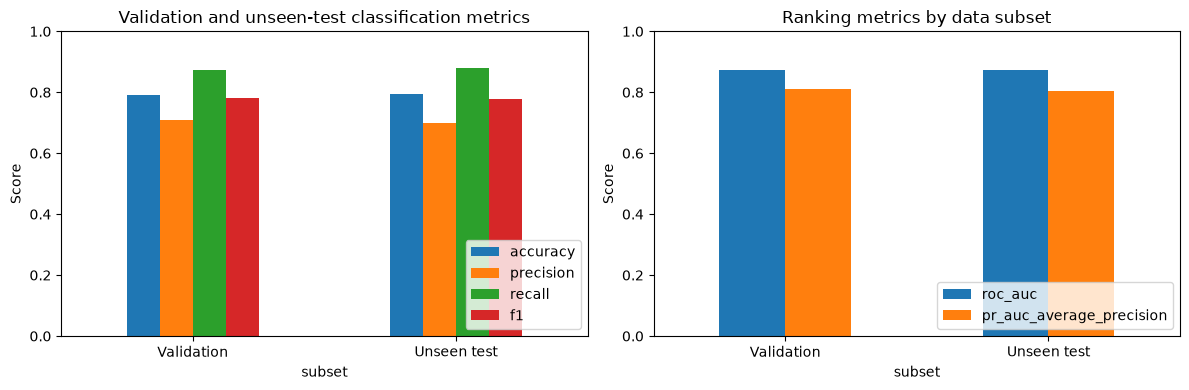

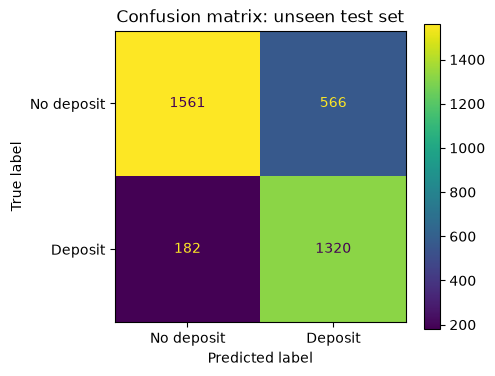

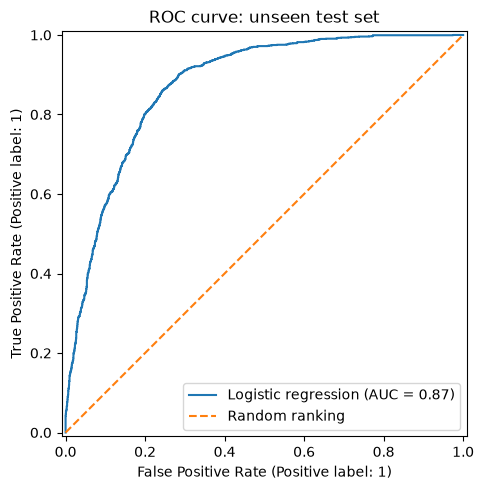

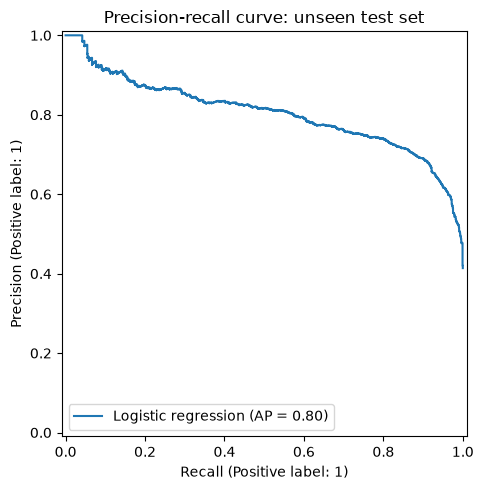

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Validation and unseen-test classification metrics")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(loc="lower right")

results[["roc_auc", "pr_auc_average_precision"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Ranking metrics by data subset")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["No deposit", "Deposit"],
    cmap=None, ax=ax
)
ax.set_title("Confusion matrix: unseen test set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
ax.set_title("ROC curve: unseen test set")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.set_title("Precision-recall curve: unseen test set")
plt.tight_layout()
plt.show()

## 9. Results, Discussion and Limitations

### 9.1 Model Performance

The logistic regression model achieved a ROC-AUC of 0.8747 and an average precision score of 0.8039 on the unseen test dataset. These results indicate that the model can distinguish between clients who deposit within 30 days and those who do not, and can rank clients according to their predicted likelihood of depositing.

The classification threshold was selected using the validation dataset by maximizing the F1-score. This produced a threshold of 0.4027 and a validation F1-score of 0.7826. The selected threshold was then applied to the unseen test dataset without using test results to tune the threshold.

At this threshold, the model achieved 79.39% accuracy, 69.99% precision, 87.88% recall and an F1-score of 0.7792 on the unseen test dataset. The recall indicates that the model identified most clients who deposited within 30 days. However, the precision indicates that some clients predicted to deposit did not actually do so. The test Brier score was 0.1398, providing an additional measure of the quality of the predicted probabilities.

The validation and test ROC-AUC scores were similar, at 0.8722 and 0.8747 respectively. The similar results are encouraging because the test set represents a later period than the training data. However, performance should continue to be monitored as client behavior and business conditions change.

### 9.2 Confusion Matrix

The unseen test dataset contained 3,629 clients, of whom 2,127 did not deposit within 30 days and 1,502 did. Using the selected threshold of 0.4027, the model produced 1,561 true negatives, 566 false positives, 182 false negatives and 1,320 true positives.

The model correctly classified 79.39% of all test clients. It correctly identified 87.88% of clients who deposited within 30 days, while its specificity was approximately 73.39%, meaning that it correctly identified this proportion of actual non-depositors.

The 566 false positives represent clients predicted to deposit who did not deposit within 30 days. These predictions could lead to time or resources being spent on clients who do not go on to fund their accounts. The 182 false negatives represent clients who deposited but were predicted not to deposit. These clients could be overlooked if the model were used to identify potential depositors.

The threshold therefore favors identifying a larger proportion of actual depositors, as reflected by the high recall, while accepting more false positives. Whether this balance is appropriate depends on the business objective and the relative cost of each type of prediction error.

### 9.3 Comparison with the KYC Baseline

A simple baseline was created by predicting that clients whose KYC status was recorded as Completed by day 3 would deposit within 30 days, while clients with other KYC statuses would not. Evaluated on the same 3,629 unseen test clients, the baseline achieved 79.17% accuracy, approximately 71% precision, 84% recall and an F1-score of approximately 77%.

Using the validation-selected classification threshold of 0.4027, the logistic regression model achieved 79.39% accuracy, 69.99% precision, 87.88% recall and an F1-score of 0.7792. The model therefore achieved slightly higher observed accuracy and recall, but slightly lower precision than the KYC baseline.

The exact McNemar test produced a p-value of 0.6154, based on 101 clients for whom the model was correct and the baseline was wrong, and 93 clients for whom the baseline was correct and the model was wrong. This result does not provide sufficient evidence of a statistically significant difference in the two methods' overall classification correctness.

The paired bootstrap 95% confidence interval for the difference in accuracy, calculated as model accuracy minus baseline accuracy, was −0.0055 to +0.0097. Because this interval includes zero, the results do not establish that the logistic regression model is more accurate than the KYC baseline. In contrast, the 95% confidence interval for the difference in recall was +0.0250 to +0.0504. Since this interval is entirely positive, the model's recall was higher than the baseline's in this paired comparison.

The logistic regression model also provides predicted probabilities, allowing clients to be ranked and the threshold to be adjusted according to business objectives. The KYC baseline produces a simpler yes-or-no prediction based on a single field. The choice between these methods should consider the need to identify more potential depositors, the cost of false positives, model complexity and the operational value of probability-based rankings.

**Fairness and subgroup performance:** The model was evaluated across age groups and provinces using the unseen test set. Recall varied across age groups, ranging from 81.67% for clients aged 24 and under to 91.67% for clients aged 55 and older. The false-positive rate also varied, from 21.24% for the youngest group to 36.36% for the 55+ group. Across provinces, recall ranged from 85.40% in the Western Cape to 93.55% in the Northern Cape, while false-positive rates ranged from 21.01% in Mpumalanga to 29.27% in the Northern Cape. These differences indicate that model performance is not identical across the evaluated groups. However, the results alone do not establish whether the model is fair or unfair. Some groups, particularly the 55+ age group and Northern Cape province, have relatively small test samples, which limits the reliability of direct comparisons. Further analysis using additional fairness measures, larger samples, and relevant contextual information would be needed before drawing conclusions about potential bias or unequal treatment.